# Anomaly Detection

Anomaly detection finds rare observations that differ from the majority. It is used for fraud,
network intrusion, equipment failure, quality control, and data-quality monitoring.

Unlike ordinary classification, anomalies are rare, labels are often unavailable, and the definition
of "normal" can change over time. This notebook covers three unsupervised detectors:

- **Isolation Forest** - isolates anomalies with random splits; anomalies need fewer splits.
- **Local Outlier Factor (LOF)** - compares local density around a point with its neighbours.
- **One-Class SVM** - learns a boundary around normal data.

## Learning objectives

1. Distinguish anomaly detection from imbalanced classification.
2. Fit and evaluate Isolation Forest, LOF, and One-Class SVM.
3. Interpret the `contamination` parameter.
4. Evaluate detectors with precision, recall, F1, and confusion matrices when labels exist.
5. Recognise the limitations of unsupervised evaluation.

## 1. Concepts

### What is an anomaly?

An anomaly is a sample that deviates from the expected pattern. It can be:

- a **point anomaly** (one unusual transaction),
- a **contextual anomaly** (high temperature in winter),
- a **collective anomaly** (a sequence of unusual events).

### Unsupervised vs supervised

- **Unsupervised**: no labels; the model estimates what is normal and flags deviations.
- **Semi-supervised**: train on normal data only, then flag deviations.
- **Supervised**: labels are available; this becomes an imbalanced classification problem.

In practice, labels are scarce, so unsupervised methods dominate.

### Contamination

`contamination` is the expected proportion of anomalies. It sets the threshold on the anomaly score.
It is a modelling assumption, not a property that can be learned from unlabelled data.

### Evaluation

With labels, use precision, recall, F1, and PR-AUC, treating anomalies as the positive class.
Without labels, evaluate with domain review, stability, and the cost of false alarms.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Create a synthetic dataset with labelled anomalies

Normal points come from a two-dimensional Gaussian. Anomalies are spread uniformly over a wider
region. We keep labels only for evaluation; the detectors do not use them during fitting.

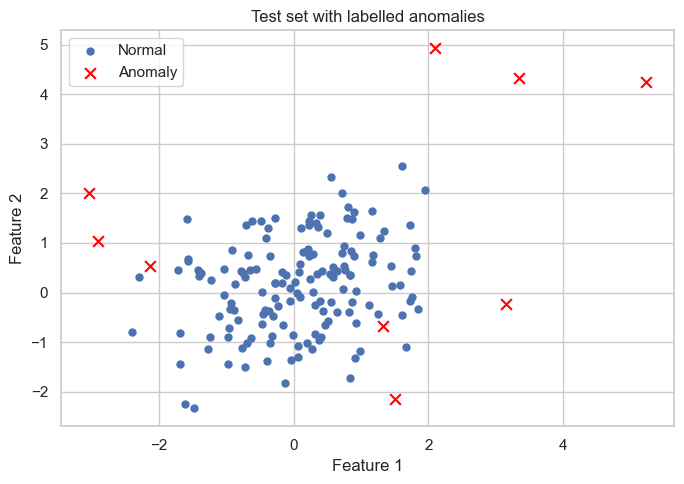

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

n_normal = 500
n_anomaly = 30

normal = rng.normal(loc=[0, 0], scale=[1, 1], size=(n_normal, 2))
anomalies = rng.uniform(low=-6, high=6, size=(n_anomaly, 2))

X = np.vstack([normal, anomalies])
y = np.r_[np.ones(n_normal), -np.ones(n_anomaly)]  # 1 = normal, -1 = anomaly

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

plt.figure(figsize=(7, 5))
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], s=25, label="Normal")
plt.scatter(X_test[y_test == -1, 0], X_test[y_test == -1, 1], s=60, color="red", marker="x", label="Anomaly")
plt.title("Test set with labelled anomalies")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Fit three detectors

All models are fitted on the training data without labels. `contamination=0.06` matches the true
anomaly rate of roughly 6%.

In [3]:
contamination = n_anomaly / (n_normal + n_anomaly)

models = {
    "Isolation Forest": IsolationForest(
        contamination=contamination, random_state=RANDOM_STATE, n_estimators=200
    ),
    "Local Outlier Factor": LocalOutlierFactor(
        contamination=contamination, novelty=True, n_neighbors=20
    ),
    "One-Class SVM": OneClassSVM(nu=contamination, kernel="rbf", gamma="scale"),
}

rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "model": name,
        "precision": precision_score(y_test, pred, pos_label=-1, zero_division=0),
        "recall": recall_score(y_test, pred, pos_label=-1, zero_division=0),
        "f1": f1_score(y_test, pred, pos_label=-1, zero_division=0),
        "flagged": int(np.sum(pred == -1)),
    })

pd.DataFrame(rows).round(4).sort_values("f1", ascending=False).reset_index(drop=True)

,model,precision,recall,f1,flagged
0,Isolation Forest,0.8571,0.6667,0.7500,7
1,Local Outlier Factor,0.7500,0.6667,0.7059,8
2,One-Class SVM,0.2000,0.5556,0.2941,25


## 5. Visualise detections

The red crosses are true anomalies. Circled points are what the model flagged. A good detector
circles the red crosses without circling too many normal points.

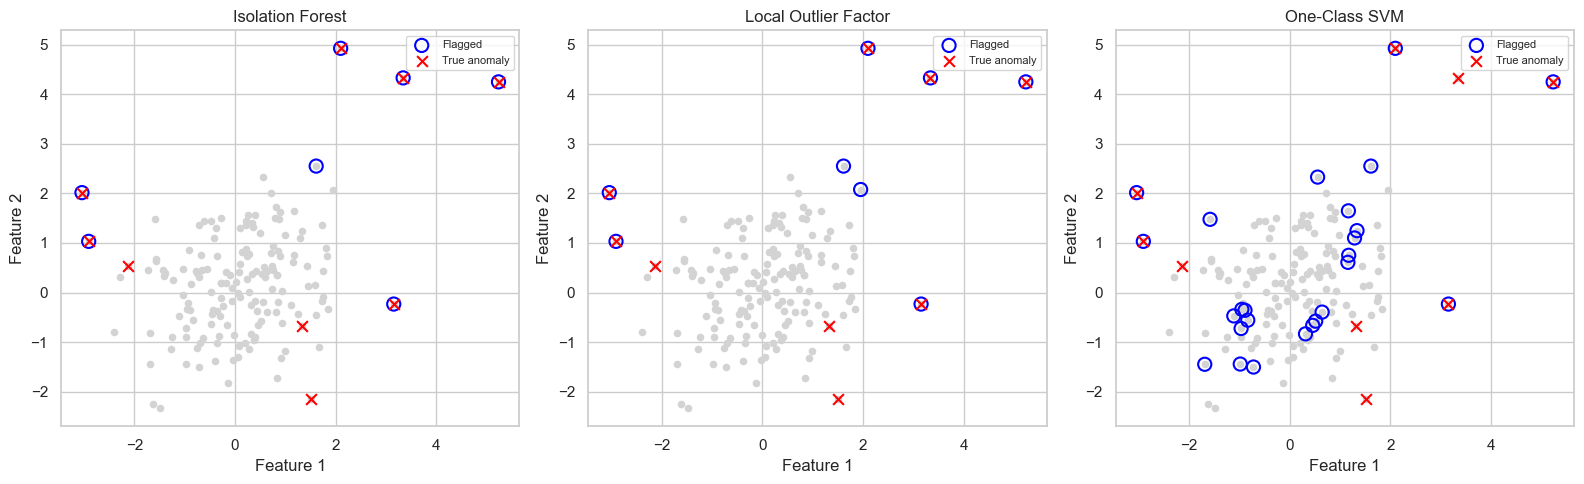

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(X_test[:, 0], X_test[:, 1], c="lightgray", s=20)
    flagged = pred == -1
    ax.scatter(X_test[flagged, 0], X_test[flagged, 1], facecolors="none",
               edgecolors="blue", s=90, linewidths=1.5, label="Flagged")
    ax.scatter(X_test[y_test == -1, 0], X_test[y_test == -1, 1],
               color="red", marker="x", s=60, label="True anomaly")
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### Confusion matrices

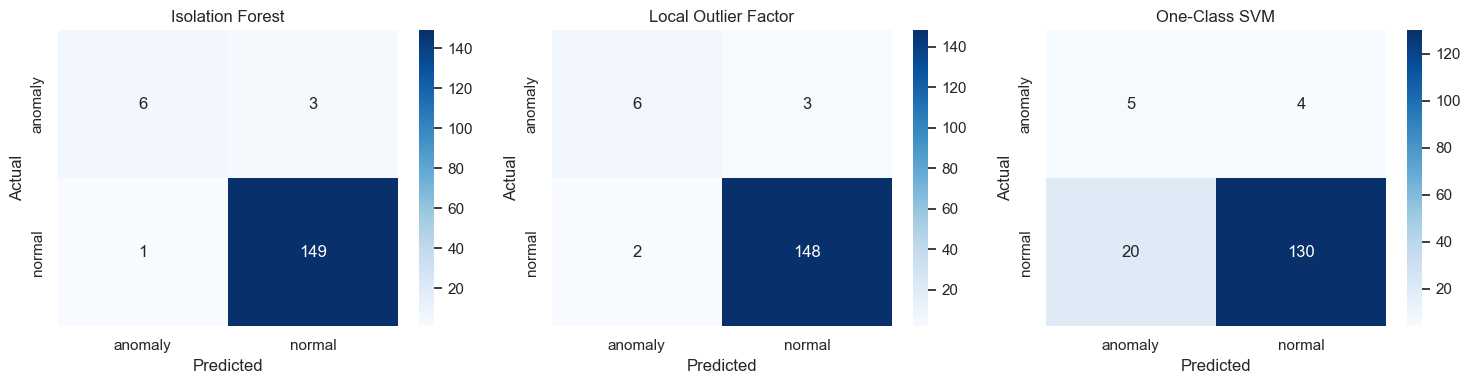

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[-1, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["anomaly", "normal"], yticklabels=["anomaly", "normal"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 6. Sensitivity to contamination

The contamination parameter directly controls how many points are flagged. If it is set too low,
recall suffers; if it is set too high, precision suffers.

In [6]:
rows = []
for value in [0.01, 0.03, 0.06, 0.10, 0.15]:
    model = IsolationForest(
        contamination=value, random_state=RANDOM_STATE, n_estimators=200
    )
    model.fit(X_train)
    pred = model.predict(X_test)
    rows.append({
        "contamination": value,
        "flag_rate": float(np.mean(pred == -1)),
        "precision": precision_score(y_test, pred, pos_label=-1, zero_division=0),
        "recall": recall_score(y_test, pred, pos_label=-1, zero_division=0),
        "f1": f1_score(y_test, pred, pos_label=-1, zero_division=0),
    })
pd.DataFrame(rows).round(4)

,contamination,flag_rate,precision,recall,f1
0,0.01,0.0063,1.0000,0.1111,0.2000
1,0.03,0.0189,1.0000,0.3333,0.5000
2,0.06,0.0440,0.8571,0.6667,0.7500
3,0.10,0.0818,0.4615,0.6667,0.5455
4,0.15,0.1195,0.4211,0.8889,0.5714


## 7. Anomaly scores

Most detectors provide a continuous score. Ranking by score is often more useful than a hard
threshold because the threshold can be chosen later to match operational capacity.

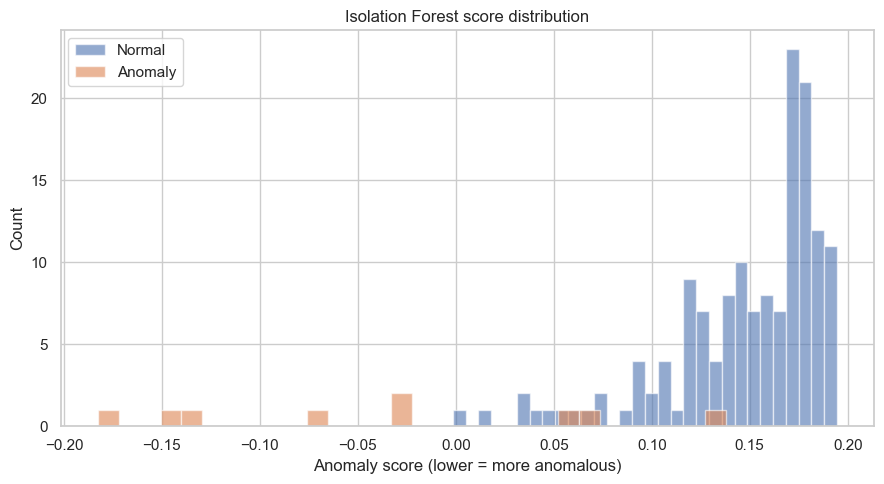

In [7]:
iso = IsolationForest(contamination=contamination, random_state=RANDOM_STATE, n_estimators=200)
iso.fit(X_train)
scores = iso.decision_function(X_test)

plt.figure(figsize=(9, 5))
plt.hist(scores[y_test == 1], bins=30, alpha=0.6, label="Normal")
plt.hist(scores[y_test == -1], bins=30, alpha=0.6, label="Anomaly")
plt.xlabel("Anomaly score (lower = more anomalous)")
plt.ylabel("Count")
plt.title("Isolation Forest score distribution")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Practical guidance

- Start with a simple detector and inspect flagged cases with domain experts.
- Estimate the expected anomaly rate before setting `contamination`.
- Scale features and avoid irrelevant dimensions; distance-based methods suffer in high dimensions.
- Use time-aware validation for temporal anomalies.
- Re-fit periodically because normal behaviour drifts.
- Combine detectors or use supervised models once enough labels exist.
- Track false-alarm cost; a detector that cries wolf is abandoned quickly.

## Key takeaways

- Anomaly detection is usually unsupervised because labels are rare.
- Isolation Forest is a strong, fast default for tabular data.
- LOF is useful for local density anomalies; One-Class SVM needs careful kernel tuning.
- `contamination` is an assumption about the anomaly rate.
- With labels, use precision, recall, F1, and PR-AUC, not accuracy.

## Exercises

1. Add a third feature with no signal and see whether detection degrades.
2. Compare `LocalOutlierFactor(n_neighbors=5)` and `n_neighbors=50`.
3. Tune `nu` and `gamma` for One-Class SVM.
4. Simulate concept drift by shifting the normal distribution in the test set.
5. Describe how you would evaluate an anomaly detector when no labels are available.